        # Cognitive Science (1204 427) — Lab 11
        ## Human Memory and the Forgetting Curve

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scipy`

        ### แนวคิดสำคัญ

        Forgetting Curve อธิบายการลดลงของ Recall ตามเวลา แบบจำลอง Exponential $P(t)=ae^{-t/\tau}+c$ ใช้ $\tau$ แทนอัตราการเสื่อมและคำนวณ Memory Half-life ได้

        ### วัตถุประสงค์

        Fit แบบจำลองความจำ เปรียบเทียบ Linear/Exponential Models และจำลองผลของ Rehearsal

        ### งานที่ต้องทำ

        1. สร้างข้อมูล Recall ตาม Delay
2. Fit Exponential Model และคำนวณ Half-life
3. เปรียบเทียบกับ Linear Model ด้วย RMSE และ AIC
4. จำลอง Rehearsal ที่เพิ่ม tau 50%
5. Required Extension: Bootstrap ช่วงความเชื่อมั่นของ Half-life

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

rng = np.random.default_rng(seed + 110)
delays = np.array([0, 5, 10, 20, 40, 80], dtype=float); n_items = 30
true_a = rng.uniform(0.65, 0.80); true_tau = rng.uniform(25, 45); true_c = rng.uniform(0.10, 0.18)
probability = np.clip(true_a * np.exp(-delays / true_tau) + true_c, 0, 1)
correct = rng.binomial(n_items, probability)
memory_df = pd.DataFrame({"delay_minutes": delays, "correct_items": correct})
memory_df["recall_rate"] = memory_df.correct_items / n_items
display(memory_df)

def forgetting_curve(t, a, tau, c):
    return a * np.exp(-t / tau) + c
params, covariance = curve_fit(forgetting_curve, delays, memory_df.recall_rate, p0=[0.7, 30, 0.1], bounds=([0, 0.1, 0], [1, 300, 1]), maxfev=10000)
a, tau, c = params; half_life = tau * np.log(2)
print(f"a={a:.4f}, tau={tau:.4f}, c={c:.4f}, half-life={half_life:.2f} min")


,delay_minutes,correct_items,recall_rate
0,0.0,29,0.966667
1,5.0,23,0.766667
2,10.0,22,0.733333
3,20.0,17,0.566667
4,40.0,12,0.400000
5,80.0,6,0.200000


a=0.7898, tau=32.8845, c=0.1415, half-life=22.79 min


,model,RMSE,AIC
0,Exponential,0.0286,-36.6532
1,Linear,0.0798,-26.3363


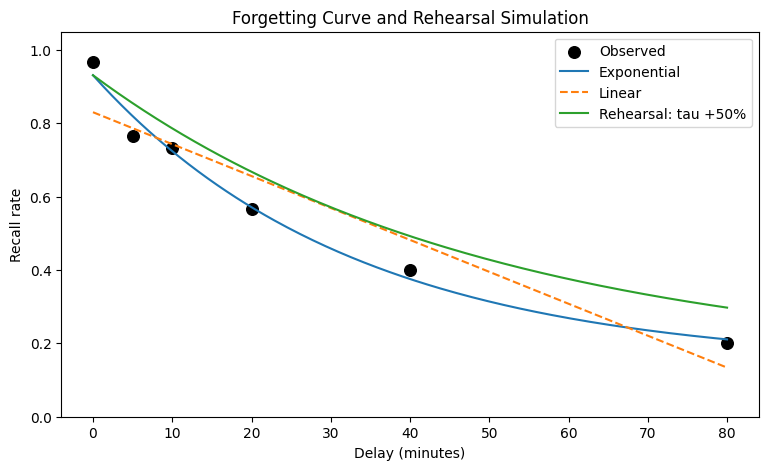

In [3]:
observed = memory_df.recall_rate.to_numpy(); exp_fit = forgetting_curve(delays, *params)
linear_params = np.polyfit(delays, observed, 1); linear_fit = np.polyval(linear_params, delays)

def rmse(y, pred): return np.sqrt(np.mean((y - pred) ** 2))
def aic(y, pred, k):
    rss = np.sum((y - pred) ** 2); n = len(y)
    return n * np.log(max(rss / n, 1e-12)) + 2 * k

model_table = pd.DataFrame({
    "model": ["Exponential", "Linear"],
    "RMSE": [rmse(observed, exp_fit), rmse(observed, linear_fit)],
    "AIC": [aic(observed, exp_fit, 3), aic(observed, linear_fit, 2)],
})
display(model_table.round(4))

grid = np.linspace(0, 80, 200)
plt.figure(figsize=(9, 5))
plt.scatter(delays, observed, color="black", s=70, label="Observed")
plt.plot(grid, forgetting_curve(grid, *params), label="Exponential")
plt.plot(grid, np.polyval(linear_params, grid), linestyle="--", label="Linear")
plt.plot(grid, forgetting_curve(grid, a, tau * 1.5, c), label="Rehearsal: tau +50%")
plt.xlabel("Delay (minutes)"); plt.ylabel("Recall rate"); plt.ylim(0, 1.05)
plt.title("Forgetting Curve and Rehearsal Simulation"); plt.legend(); plt.show()


## Required Extension

ใช้ Parametric Bootstrap อย่างน้อย 500 รอบเพื่อประมาณ 95% CI ของ Half-life โดยสุ่มจำนวนคำที่จำได้จาก Binomial Distribution แล้ว Fit Model ใหม่ในแต่ละรอบ


Point estimate half-life = 22.79 min
Bootstrap 95% CI = [11.37, 42.95] min (n=500 fits)


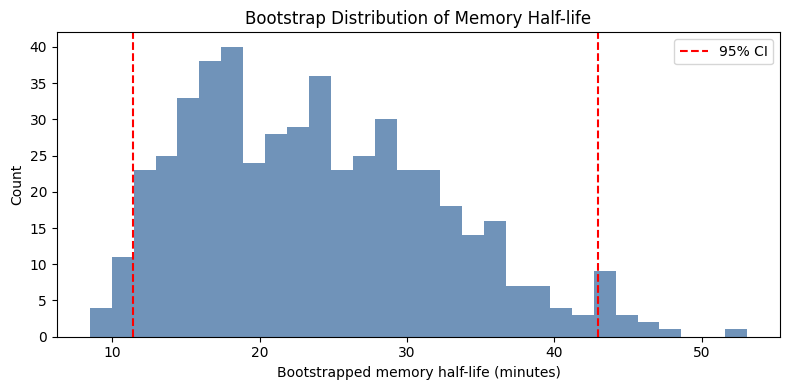

In [4]:
# ===== Required Extension: Parametric Bootstrap ของ Half-life =====
boot_rng = np.random.default_rng(seed + 111)
fitted_prob = np.clip(forgetting_curve(delays, *params), 0, 1)
bootstrap_half_lives = []
for _ in range(500):
    boot_recall = boot_rng.binomial(n_items, fitted_prob) / n_items
    try:
        bp, _ = curve_fit(forgetting_curve, delays, boot_recall, p0=params,
                          bounds=([0, 0.1, 0], [1, 300, 1]), maxfev=10000)
        bootstrap_half_lives.append(bp[1] * np.log(2))
    except RuntimeError:
        pass

bootstrap_half_lives = np.array(bootstrap_half_lives)
ci_low, ci_high = np.percentile(bootstrap_half_lives, [2.5, 97.5])
print(f"Point estimate half-life = {half_life:.2f} min")
print(f"Bootstrap 95% CI = [{ci_low:.2f}, {ci_high:.2f}] min (n={len(bootstrap_half_lives)} fits)")

plt.figure(figsize=(8, 4))
plt.hist(bootstrap_half_lives, bins=30, color="#4c78a8", alpha=0.8)
plt.axvline(ci_low, color="red", linestyle="--", label="95% CI")
plt.axvline(ci_high, color="red", linestyle="--")
plt.xlabel("Bootstrapped memory half-life (minutes)")
plt.ylabel("Count")
plt.title("Bootstrap Distribution of Memory Half-life")
plt.legend()
plt.tight_layout()
plt.show()


## คำถามวิเคราะห์ Lab 11

**1. Exponential หรือ Linear Model เหมาะสมกว่าเมื่อพิจารณา RMSE และ AIC**

Exponential เหมาะกว่าชัดเจนครับ RMSE ต่ำกว่ามาก (~0.029 vs ~0.080) และ AIC ก็ต่ำกว่า (~-37 vs ~-26) ทั้งสองเกณฑ์ชี้ไปทางเดียวกันว่าเส้นโค้งทวีคูณจับรูปแบบการลืมได้ดีกว่าเส้นตรง ตรงกับที่ว่าความจำลดเร็วช่วงแรกแล้วค่อยๆ ช้าลง

**2. a, tau, c และ Half-life มีความหมายอย่างไร**

a (~0.79) คือสัดส่วนความจำเริ่มต้นที่เสื่อมได้, tau (~32.9 นาที) คือค่าคงที่เวลาที่คุมอัตราการลืม (ยิ่งมากลืมช้า), c (~0.14) คือระดับพื้นฐานที่ recall เข้าใกล้เมื่อเวลานานมาก (ความจำคงเหลือ/เดา), Half-life (~22.8 นาที = tau·ln2) คือเวลาที่ส่วนที่เสื่อมได้ลดเหลือครึ่ง

**3. Rehearsal เปลี่ยน Predicted Recall อย่างไร**

การเพิ่ม tau 50% ทำให้เส้นโค้งลาดลงช้ากว่าเดิม recall ที่เวลาเดียวกันสูงขึ้น (โดยเฉพาะช่วงกลางๆ) แสดงว่าการทบทวนไม่ได้เพิ่มปริมาณเริ่มต้น (a เท่าเดิม) แต่ทำให้ความจำทนทานขึ้น ลืมช้าลง ตรงกับหลักการ consolidation

**4. Bootstrap CI กว้างหรือแคบ และสะท้อนความไม่แน่นอนอะไร**

ค่อนข้างกว้างครับ 95% CI ของ half-life ราว [11, 43] นาที (จุดประมาณ ~23) สะท้อนว่าเรามีจุดข้อมูลแค่ 6 delay และแต่ละจุดมาจาก binomial 30 items เลยมี noise เยอะ การประมาณ tau/half-life จึงไม่แน่นอนสูง ต้องระวังการตีความค่าเดียวแบบเป๊ะๆ

**5. แบบจำลองนี้ละเลยกระบวนการความจำใดบ้าง**

ละเลย consolidation ระหว่างนอน, interference จากข้อมูลอื่น, ผลของ retrieval practice, spacing effect, และความแตกต่างของประเภทสิ่งที่จำ (คำ/ภาพ/ความหมาย) โมเดลมองการลืมเป็นเส้นเดียวจากเวลาอย่างเดียว ซึ่งง่ายกว่าความจำจริงมาก

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอนทำ parametric bootstrap เพราะต้อง fit โมเดลใหม่ 500 รอบและต้องดัก error เวลา curve_fit ไม่ลู่เข้า ตอนแรกลืม try/except เลยพังกลางทาง พอใส่แล้วรันผ่าน เห็น distribution ของ half-life ชัดขึ้น

สิ่งที่เข้าใจมากขึ้นคือค่า half-life ที่ได้มันไม่ได้แม่นอย่างที่คิด พอดู CI กว้างถึง [11,43] นาที ทำให้ระวังการรายงานเลขตัวเดียวโดยไม่บอกความไม่แน่นอน และเข้าใจว่าทำไมงานวิจัยความจำต้องเก็บข้อมูลเยอะๆ

ถ้าทำซ้ำ อยากเพิ่มจำนวน delay และจำนวน items ต่อจุดเพื่อให้ CI แคบลง และลองเก็บข้อมูลหลายคนมา fit รายบุคคลเทียบกัน น่าจะเห็นความต่างของอัตราการลืมระหว่างคน

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
